# Comparative Analysis of RNN, LSTM and GRU for Tourism Demand Prediction

**Goal:** Forecast national daily tourism demand (total tourist arrivals across all tracked tourist sites) and compare Simple RNN, LSTM, and GRU architectures under identical, fair conditions to determine which model generalizes best.

**Workflow:**
1. Load and understand the dataset
2. Clean and preprocess the data
3. Exploratory Data Analysis (EDA)
4. Build leak-free time-series sequences
5. Train RNN, LSTM, GRU under identical conditions
6. Evaluate with MAE, RMSE, MAPE, R², and training time
7. Compare results (tables + plots)
8. Select the best model based on actual metrics
9. Forecast future tourism demand with the best model
10. Conclusion

**About the data:** The raw file (`train_df.csv`) is *panel data* — daily tourist-arrival counts for 432 site combinations (54 `tourist_area` × 8 `spot_facility` types), spanning 2018-08-01 to 2019-05-31. We define **"tourism demand"** as the **national daily total**: the sum of `tourist_arrivals` across all 432 sites for each calendar day. This gives one clean, interpretable univariate series suitable for sequence modeling.

We do **not** use the competition's `test_df.csv` / `submission.csv` for evaluation, since `submission.csv` contains no true labels (it's a blank template) and `test_df.csv` covers a disjoint future window (2019-07) with a gap after training data ends. Instead, we build our own chronological train/validation/test split directly from `train_df.csv` in Stage 4.


## Stage 1 — Load and Understand the Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
plt.rcParams['figure.figsize'] = (12, 4)

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print("Libraries loaded.")

Libraries loaded.


In [2]:
# Load the raw panel dataset
raw = pd.read_csv('train_df.csv', parse_dates=['date'])
print("Shape:", raw.shape)
raw.head()

Shape: (132192, 13)


,id,date,tourist_area,spot_facility,tourist_arrivals,area,city,type,category,tourism_index,info,event,weather_index
0,0,2018-08-01,1,A,454,A,A,A,13,1750.0,A,A,40.05
1,1,2018-08-01,1,B,823,A,A,A,13,1750.0,A,A,40.05
2,2,2018-08-01,1,C,149,A,A,A,13,1750.0,A,A,40.05
3,3,2018-08-01,1,D,157,A,A,A,13,1750.0,A,A,40.05
4,4,2018-08-01,1,E,14,A,A,A,13,1750.0,A,A,40.05


In [3]:
raw.dtypes

id                           int64
date                datetime64[us]
tourist_area                 int64
spot_facility                  str
tourist_arrivals             int64
area                           str
city                           str
type                           str
category                     int64
tourism_index              float64
info                           str
event                          str
weather_index              float64
dtype: object

In [4]:
# How granular is the panel? One row = one (date, tourist_area, spot_facility) combination
print("Unique dates          :", raw['date'].nunique())
print("Unique tourist_area   :", raw['tourist_area'].nunique())
print("Unique spot_facility  :", raw['spot_facility'].nunique())
print("Unique (area, facility) combos:", raw.groupby(['tourist_area', 'spot_facility']).ngroups)
print("Date range            :", raw['date'].min().date(), "to", raw['date'].max().date())

Unique dates          : 303
Unique tourist_area   : 54
Unique spot_facility  : 8
Unique (area, facility) combos: 432
Date range            : 2018-08-01 to 2019-05-31


In [5]:
# Missing values in the raw panel
raw.isna().sum().to_frame('missing_count').assign(
    missing_pct=lambda d: (d['missing_count'] / len(raw) * 100).round(2)
)

,missing_count,missing_pct
id,0,0.00
date,0,0.00
tourist_area,0,0.00
spot_facility,0,0.00
tourist_arrivals,0,0.00
area,0,0.00
city,0,0.00
type,0,0.00
category,0,0.00
tourism_index,3992,3.02


In [6]:
# Basic stats on the raw target column (site-level, not yet aggregated)
raw['tourist_arrivals'].describe()

count    132192.000000
mean        347.174708
std         449.542388
min           0.000000
25%          75.000000
50%         202.000000
75%         443.000000
max        6308.000000
Name: tourist_arrivals, dtype: float64

### Build the national daily demand series
Sum `tourist_arrivals` across all 432 site combinations for each date.

In [7]:
daily = raw.groupby('date')['tourist_arrivals'].sum().sort_index()

full_range = pd.date_range(daily.index.min(), daily.index.max(), freq='D')
missing_days = full_range.difference(daily.index)
print("Days present   :", len(daily))
print("Full span      :", len(full_range), "calendar days")
print("Missing days   :", list(missing_days))

Days present   : 303
Full span      : 304 calendar days
Missing days   : [Timestamp('2018-12-25 00:00:00')]


In [8]:
daily = daily.reindex(full_range)
daily.index.name = 'date'
daily.name = 'tourist_arrivals'

print(daily.isna().sum(), "missing value(s) after reindexing")
daily.describe()

1 missing value(s) after reindexing


count       303.000000
mean     151464.419142
std       36686.731720
min        2622.000000
25%      128021.000000
50%      143031.000000
75%      169761.000000
max      340846.000000
Name: tourist_arrivals, dtype: float64

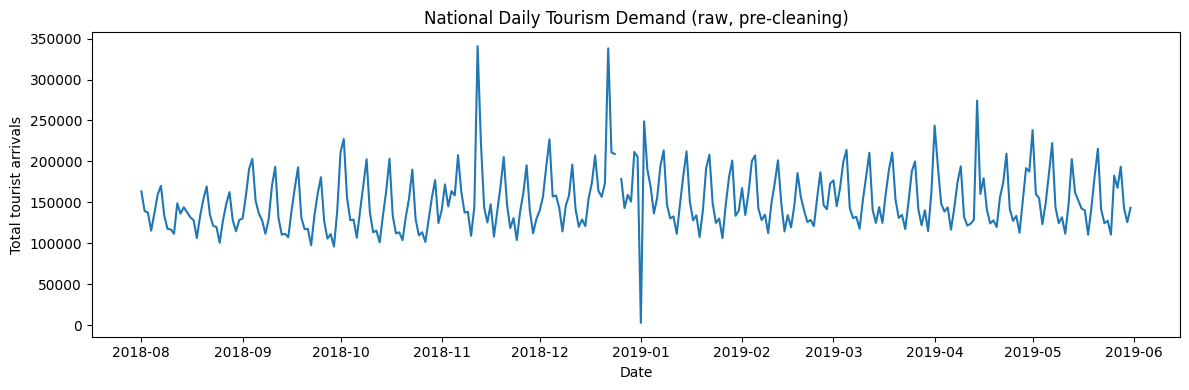

In [9]:
plt.plot(daily.index, daily.values)
plt.title('National Daily Tourism Demand (raw, pre-cleaning)')
plt.xlabel('Date'); plt.ylabel('Total tourist arrivals')
plt.tight_layout(); plt.savefig('stage1_raw_series.png', dpi=100); plt.show()

### Stage 1 findings
- The raw file is site-level panel data; we aggregated it into a **single national daily series of length 304** (2018-08-01 → 2019-05-31), with **exactly one missing day** (2018-12-25 — plausibly a data-collection gap, e.g. sites closed/unreported on Christmas).
- No missing values in the raw `tourist_arrivals` column itself — the panel is complete except for that one calendar date.
- The series shows a clear seasonal pattern with a visible dip in winter — worth digging into in the EDA stage.


## Stage 2 — Cleaning & Preprocessing

In [10]:
raw = pd.read_csv('train_df.csv', parse_dates=['date'])
daily = raw.groupby('date')['tourist_arrivals'].sum().sort_index()
full_range = pd.date_range(daily.index.min(), daily.index.max(), freq='D')
daily = daily.reindex(full_range)
daily.index.name = 'date'
daily.name = 'tourist_arrivals'
daily.isna().sum()

np.int64(1)

**Handling the missing day (2018-12-25):** it's a single isolated gap in an otherwise complete daily series. Dropping it would break the fixed daily frequency our sequence models rely on, and a single day has negligible impact on a 304-day series. We use **linear interpolation** between 2018-12-24 and 2018-12-26 — a standard, low-bias way to fill a single-day gap in a continuous series (no lookahead risk since both neighbors are real observed values, not future targets we're trying to predict).

In [11]:
before, after = daily.loc['2018-12-24'], daily.loc['2018-12-26']
print("Value on 2018-12-24:", before)
print("Value on 2018-12-26:", after)

daily = daily.interpolate(method='time')
print("Value filled on 2018-12-25:", round(daily.loc['2018-12-25'], 1))
print("Remaining missing values:", daily.isna().sum())

Value on 2018-12-24: 209086.0
Value on 2018-12-26: 178649.0
Value filled on 2018-12-25: 193867.5
Remaining missing values: 0


### Outlier check
Using the IQR rule as a diagnostic (not to blindly remove points — tourism demand can legitimately spike for holidays/events).

In [12]:
q1, q3 = daily.quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = daily[(daily < lower) | (daily > upper)]
print(f"IQR bounds: [{lower:.0f}, {upper:.0f}]")
print(f"Number of flagged points: {len(outliers)}")
outliers.to_frame('tourist_arrivals')

IQR bounds: [64935, 233209]
Number of flagged points: 7


,tourist_arrivals
date,
2018-11-12,340846.0
2018-12-22,338176.0
2019-01-01,2622.0
2019-01-02,248962.0
2019-04-01,243811.0
2019-04-14,274394.0
2019-05-01,238246.0


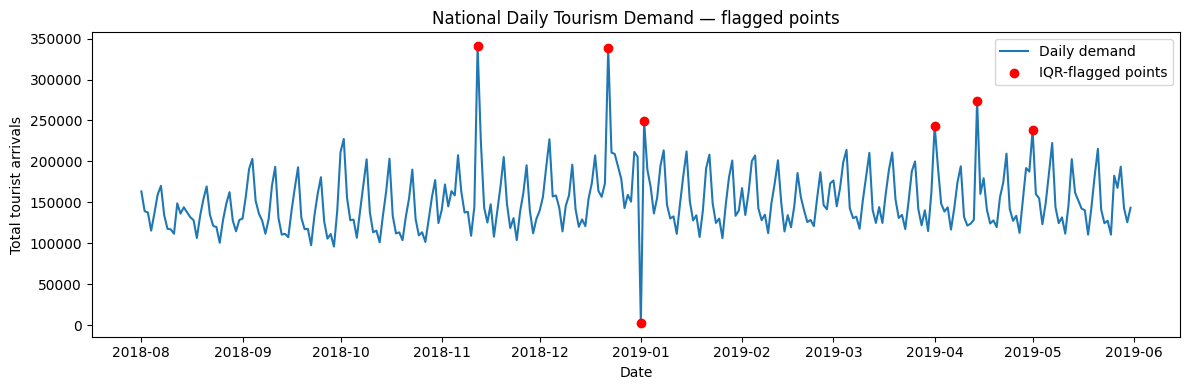

In [13]:
plt.plot(daily.index, daily.values, label='Daily demand')
plt.scatter(outliers.index, outliers.values, color='red', zorder=5, label='IQR-flagged points')
plt.title('National Daily Tourism Demand — flagged points')
plt.xlabel('Date'); plt.ylabel('Total tourist arrivals'); plt.legend()
plt.tight_layout(); plt.savefig('stage2_outliers.png', dpi=100); plt.show()

**Decision:** the flagged low points cluster in the winter off-season (genuine seasonal lows, not data errors) and are far from the interpolated 12-25 value, so nothing here looks like a sensor error or duplicate-entry artifact. We keep all points as-is — removing them would delete real demand patterns the models need to learn. No values are dropped or clipped.


In [14]:
daily.to_frame().to_csv('daily_cleaned.csv')
daily.describe()

count       304.000000
mean     151603.902961
std       36706.795828
min        2622.000000
25%      128037.500000
50%      143090.500000
75%      170106.000000
max      340846.000000
Name: tourist_arrivals, dtype: float64

## Stage 3 — Exploratory Data Analysis (EDA)

In [15]:
daily = pd.read_csv('daily_cleaned.csv', index_col=0, parse_dates=True)['tourist_arrivals']
daily.index.freq = 'D'
print(daily.shape)
daily.head()

(304,)


date
2018-08-01    163326.0
2018-08-02    139225.0
2018-08-03    137514.0
2018-08-04    115340.0
2018-08-05    136706.0
Freq: D, Name: tourist_arrivals, dtype: float64

### Overall trend with rolling statistics

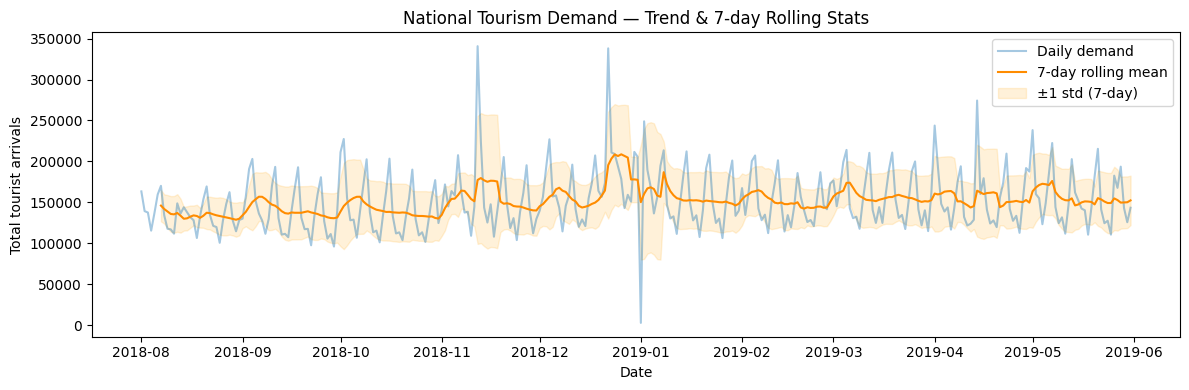

In [16]:
roll_mean = daily.rolling(7).mean()
roll_std = daily.rolling(7).std()

plt.plot(daily.index, daily.values, alpha=0.4, label='Daily demand')
plt.plot(roll_mean.index, roll_mean.values, color='darkorange', label='7-day rolling mean')
plt.fill_between(roll_std.index, roll_mean - roll_std, roll_mean + roll_std,
                  color='orange', alpha=0.15, label='±1 std (7-day)')
plt.title('National Tourism Demand — Trend & 7-day Rolling Stats')
plt.xlabel('Date'); plt.ylabel('Total tourist arrivals'); plt.legend()
plt.tight_layout(); plt.savefig('eda_trend.png', dpi=100); plt.show()

### Day-of-week seasonality

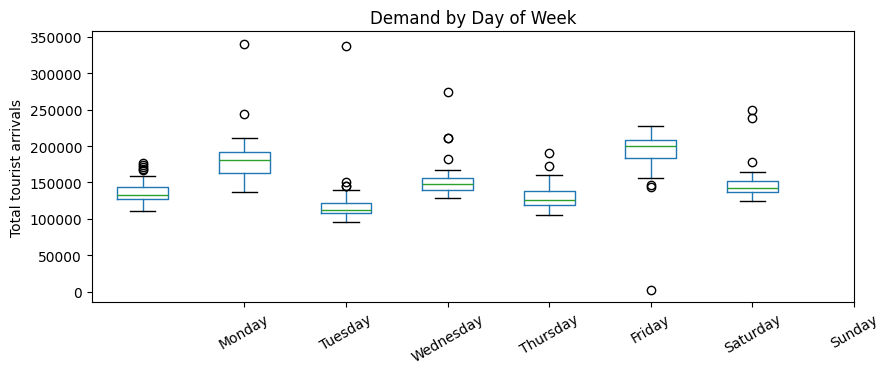

weekday
Monday       182511.232558
Tuesday      191025.732558
Wednesday    148157.204545
Thursday     130000.931818
Friday       135867.613636
Saturday     121429.116279
Sunday       153184.000000
Name: tourist_arrivals, dtype: float64

In [17]:
dow = daily.to_frame().copy()
dow['weekday'] = dow.index.day_name()
order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

fig, ax = plt.subplots(figsize=(9, 4))
dow.boxplot(column='tourist_arrivals', by='weekday', ax=ax,
            positions=range(7), grid=False)
ax.set_xticks(range(1, 8))
ax.set_xticklabels(order, rotation=30)
ax.set_title('Demand by Day of Week'); plt.suptitle('')
ax.set_xlabel(''); ax.set_ylabel('Total tourist arrivals')
plt.tight_layout(); plt.savefig('eda_dow.png', dpi=100); plt.show()

dow.groupby('weekday')['tourist_arrivals'].mean().reindex(order)

### Monthly demand levels

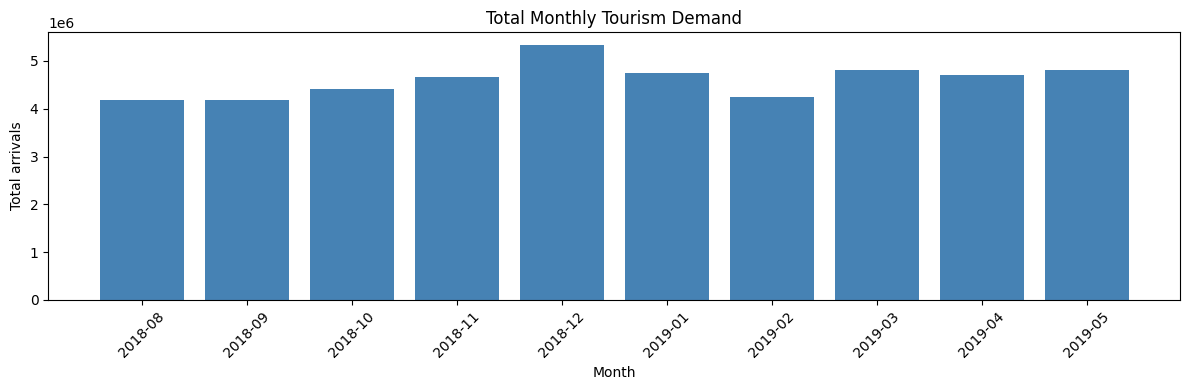

In [18]:
monthly = daily.resample('MS').sum()
plt.bar(monthly.index.strftime('%Y-%m'), monthly.values, color='steelblue')
plt.title('Total Monthly Tourism Demand')
plt.xlabel('Month'); plt.ylabel('Total arrivals'); plt.xticks(rotation=45)
plt.tight_layout(); plt.savefig('eda_monthly.png', dpi=100); plt.show()

### Distribution of daily demand

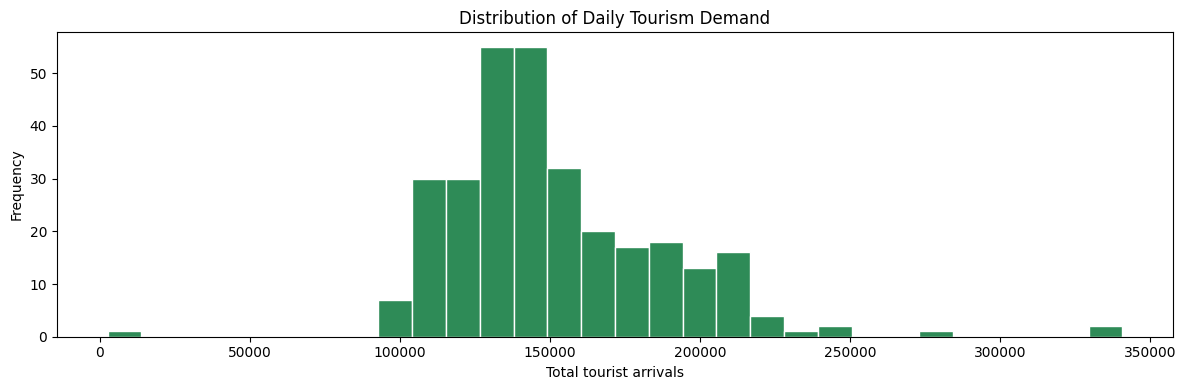

Skewness: 1.186


In [19]:
plt.hist(daily.values, bins=30, color='seagreen', edgecolor='white')
plt.title('Distribution of Daily Tourism Demand')
plt.xlabel('Total tourist arrivals'); plt.ylabel('Frequency')
plt.tight_layout(); plt.savefig('eda_hist.png', dpi=100); plt.show()
print("Skewness:", round(daily.skew(), 3))

### Seasonal decomposition & autocorrelation
We decompose the series (weekly period = 7, matching the day-of-week pattern above) and inspect ACF/PACF to sanity-check how much lookback the sequence models should reasonably need.

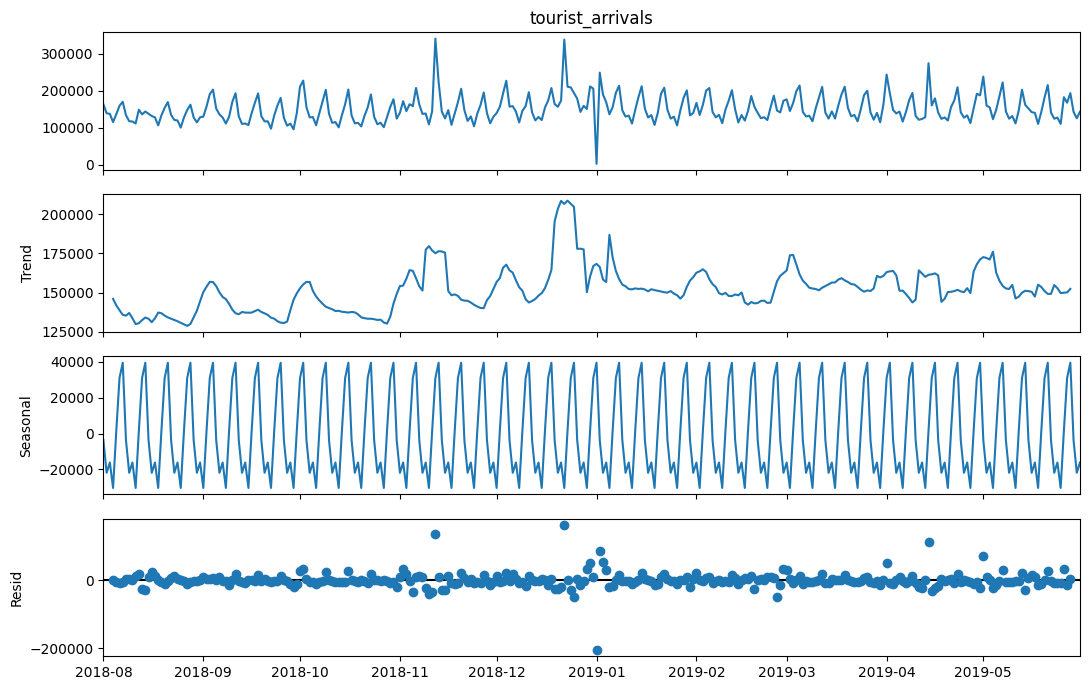

In [20]:
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

decomp = seasonal_decompose(daily, model='additive', period=7)
fig = decomp.plot()
fig.set_size_inches(11, 7)
plt.tight_layout(); plt.savefig('eda_decompose.png', dpi=100); plt.show()

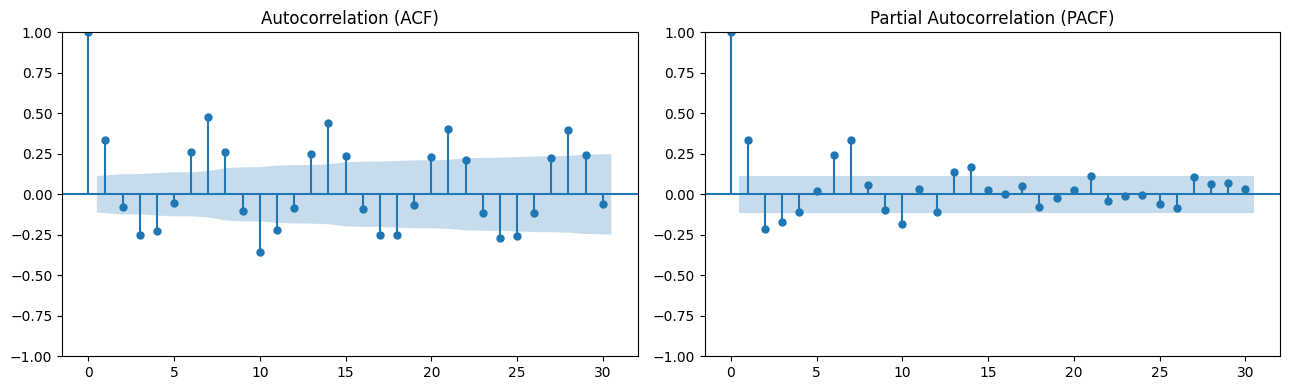

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
plot_acf(daily, lags=30, ax=ax[0])
plot_pacf(daily, lags=30, ax=ax[1], method='ywm')
ax[0].set_title('Autocorrelation (ACF)')
ax[1].set_title('Partial Autocorrelation (PACF)')
plt.tight_layout(); plt.savefig('eda_acf_pacf.png', dpi=100); plt.show()

### Stage 3 findings
- Clear **weekly seasonality**: demand is consistently higher on weekends and lower midweek.
- Clear **seasonal/trend dip** in winter months (Dec–Feb) visible in both the raw plot and the decomposition, consistent with an off-season travel pattern.
- The distribution is right-skewed with a cluster of high-demand weekend/holiday peaks.
- ACF shows a clear repeating pattern near lag 7 (confirming weekly seasonality); PACF shows strong short-lag dependence. This supports using a **lookback window that spans at least 2 full weeks (14 days)** so the models can see complete weekly cycles — the choice we'll use in Stage 4.


## Stage 4 — Prepare Time-Series Sequences (No Data Leakage)

**Leakage-prevention rules we follow:**
1. **Chronological split** — no shuffling before splitting. Train covers the earliest dates, validation the next, test the most recent. We never train on data that is chronologically after what we validate/test on.
2. **Scaler fit on train only** — `MinMaxScaler` is fit exclusively on the training portion, then applied (`transform`, never `fit`) to validation and test. This prevents future min/max values from leaking statistical information into training.
3. **Windows built from real past values only** — each input sequence uses only observed values *before* the day being predicted. A window is allowed to reach back across the train/val boundary (those are real historical observations, not the label being predicted), but a sample's **target date** determines which split it belongs to.


In [22]:
daily = pd.read_csv('daily_cleaned.csv', index_col=0, parse_dates=True)['tourist_arrivals']
values = daily.values.astype('float32').reshape(-1, 1)
n = len(values)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

print(f"Total days: {n}")
print(f"Train: {train_end} days  ({daily.index[0].date()} -> {daily.index[train_end-1].date()})")
print(f"Val:   {val_end - train_end} days  ({daily.index[train_end].date()} -> {daily.index[val_end-1].date()})")
print(f"Test:  {n - val_end} days  ({daily.index[val_end].date()} -> {daily.index[-1].date()})")

Total days: 304
Train: 212 days  (2018-08-01 -> 2019-02-28)
Val:   46 days  (2019-03-01 -> 2019-04-15)
Test:  46 days  (2019-04-16 -> 2019-05-31)


In [23]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(values[:train_end])          # fit on TRAIN ONLY
scaled = scaler.transform(values)       # transform the full series with train-derived params
print("Scaler fitted on train only. Train min/max used:",
      scaler.data_min_[0], scaler.data_max_[0])

Scaler fitted on train only. Train min/max used: 2622.0 340846.0


In [24]:
WINDOW = 14  # 2 full weeks, motivated by the weekly seasonality found in Stage 3

def make_windows(series_scaled, window, target_start, target_end):
    """Build (X, y) where each y is at index i (target_start <= i < target_end)
    and X is series_scaled[i-window : i]. Requires i-window >= 0."""
    X, y, dates = [], [], []
    for i in range(max(target_start, window), target_end):
        X.append(series_scaled[i - window:i, 0])
        y.append(series_scaled[i, 0])
        dates.append(daily.index[i])
    return np.array(X), np.array(y), dates

X_train, y_train, dates_train = make_windows(scaled, WINDOW, 0, train_end)
X_val, y_val, dates_val = make_windows(scaled, WINDOW, train_end, val_end)
X_test, y_test, dates_test = make_windows(scaled, WINDOW, val_end, n)

X_train = X_train.reshape(-1, WINDOW, 1)
X_val = X_val.reshape(-1, WINDOW, 1)
X_test = X_test.reshape(-1, WINDOW, 1)

print("X_train:", X_train.shape, " y_train:", y_train.shape)
print("X_val:  ", X_val.shape, " y_val:  ", y_val.shape)
print("X_test: ", X_test.shape, " y_test: ", y_test.shape)
print()
print("First train target date:", dates_train[0].date())
print("First val target date:  ", dates_val[0].date(), " (window reaches back into train — expected, not leakage)")
print("First test target date: ", dates_test[0].date())

X_train: (198, 14, 1)  y_train: (198,)
X_val:   (46, 14, 1)  y_val:   (46,)
X_test:  (46, 14, 1)  y_test:  (46,)

First train target date: 2018-08-15
First val target date:   2019-03-01  (window reaches back into train — expected, not leakage)
First test target date:  2019-04-16


Note the val/test window counts are slightly smaller than a naive `0.15 * n` because the first `WINDOW` days of the whole series can't form a full 14-day lookback — those days are simply unusable as prediction targets, which is expected and correct.

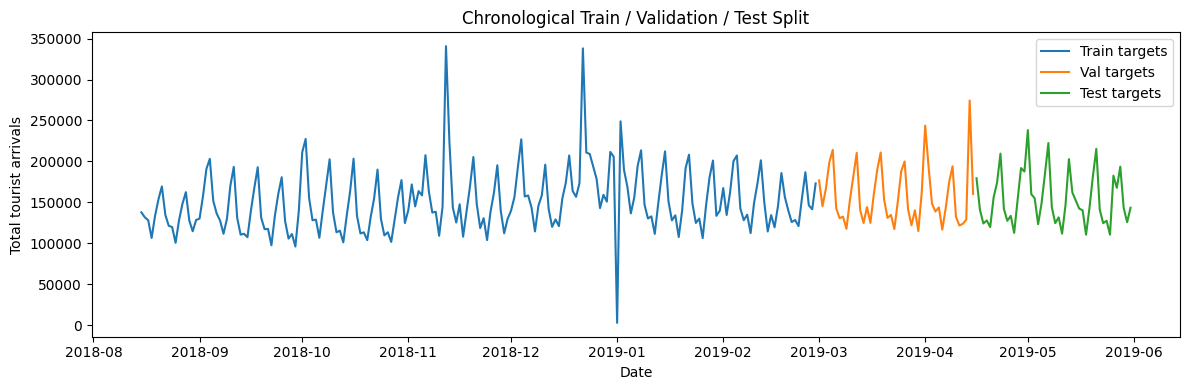

In [25]:
plt.figure(figsize=(12, 4))
plt.plot(dates_train, scaler.inverse_transform(y_train.reshape(-1, 1)), label='Train targets')
plt.plot(dates_val, scaler.inverse_transform(y_val.reshape(-1, 1)), label='Val targets')
plt.plot(dates_test, scaler.inverse_transform(y_test.reshape(-1, 1)), label='Test targets')
plt.title('Chronological Train / Validation / Test Split')
plt.xlabel('Date'); plt.ylabel('Total tourist arrivals'); plt.legend()
plt.tight_layout(); plt.savefig('stage4_split.png', dpi=100); plt.show()

In [26]:
import pickle
with open('sequences.pkl', 'wb') as f:
    pickle.dump({
        'X_train': X_train, 'y_train': y_train, 'dates_train': dates_train,
        'X_val': X_val, 'y_val': y_val, 'dates_val': dates_val,
        'X_test': X_test, 'y_test': y_test, 'dates_test': dates_test,
        'scaler': scaler, 'window': WINDOW, 'daily': daily,
    }, f)
print("Sequences and scaler saved to sequences.pkl")

Sequences and scaler saved to sequences.pkl


In [27]:
print("Stage 4 summary")
print(f"  Chronological 70/15/15 split, scaler fit strictly on the training portion.")
print(f"  14-day sliding windows (WINDOW={WINDOW}), one target per window, no shuffling before splitting.")
print(f"  Train: {X_train.shape[0]} samples | Val: {X_val.shape[0]} samples | Test: {X_test.shape[0]} samples.")

Stage 4 summary
  Chronological 70/15/15 split, scaler fit strictly on the training portion.
  14-day sliding windows (WINDOW=14), one target per window, no shuffling before splitting.
  Train: 198 samples | Val: 46 samples | Test: 46 samples.


## Stage 5 — Train RNN, LSTM and GRU Under Identical, Fair Conditions

To make this a **fair** comparison, all three models share:
- the same input data (`sequences.pkl` from Stage 4)
- the same architecture shape: **one recurrent layer (32 units) → Dropout(0.2) → Dense(1)**
- the same optimizer (Adam, lr=0.001), loss (MSE), batch size (16), max epochs (200)
- the same `EarlyStopping` (on `val_loss`, patience=15, restores best weights)
- the same random seed, reset immediately before building each model

Only the recurrent layer type (`SimpleRNN` vs `LSTM` vs `GRU`) differs between the three runs.

In [28]:
import pickle, time, random
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, GRU, Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping

with open('sequences.pkl', 'rb') as f:
    seq = pickle.load(f)

X_train, y_train = seq['X_train'], seq['y_train']
X_val, y_val = seq['X_val'], seq['y_val']
X_test, y_test = seq['X_test'], seq['y_test']
scaler, WINDOW = seq['scaler'], seq['window']

SEED = 42
UNITS = 32
EPOCHS = 200
BATCH_SIZE = 16
PATIENCE = 15

def set_seeds(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

print("Environment ready. TF version:", tf.__version__)

I0000 00:00:1788378535.641825   10905 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1788378535.687147   10905 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1788378537.173623   10905 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Environment ready. TF version: 2.21.0


In [29]:
def build_model(layer_type):
    set_seeds(SEED)  # reset before every model so initialization conditions match
    layer_cls = {'RNN': SimpleRNN, 'LSTM': LSTM, 'GRU': GRU}[layer_type]
    model = Sequential([
        Input(shape=(WINDOW, 1)),
        layer_cls(UNITS, activation='tanh'),
        Dropout(0.2),
        Dense(1),
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='mse')
    return model

build_model('LSTM').summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,385 (17.13 KB)

 Trainable params: 4,385 (17.13 KB)

 Non-trainable params: 0 (0.00 B)

In [30]:
def train_model(layer_type):
    set_seeds(SEED)
    model = build_model(layer_type)
    es = EarlyStopping(monitor='val_loss', patience=PATIENCE, restore_best_weights=True)

    start = time.time()
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[es],
        verbose=0,
    )
    elapsed = time.time() - start
    n_epochs = len(history.history['loss'])
    best_val = min(history.history['val_loss'])
    print(f"{layer_type:5s} | stopped at epoch {n_epochs:3d} | "
          f"best val_loss={best_val:.5f} | training time={elapsed:.1f}s")
    return model, history, elapsed

In [31]:
results = {}
for layer_type in ['RNN', 'LSTM', 'GRU']:
    model, history, elapsed = train_model(layer_type)
    results[layer_type] = {'model': model, 'history': history, 'train_time': elapsed}
print("\nAll three models trained.")

RNN   | stopped at epoch  24 | best val_loss=0.00635 | training time=4.9s


LSTM  | stopped at epoch 200 | best val_loss=0.00860 | training time=32.5s


GRU   | stopped at epoch 200 | best val_loss=0.00621 | training time=33.3s

All three models trained.


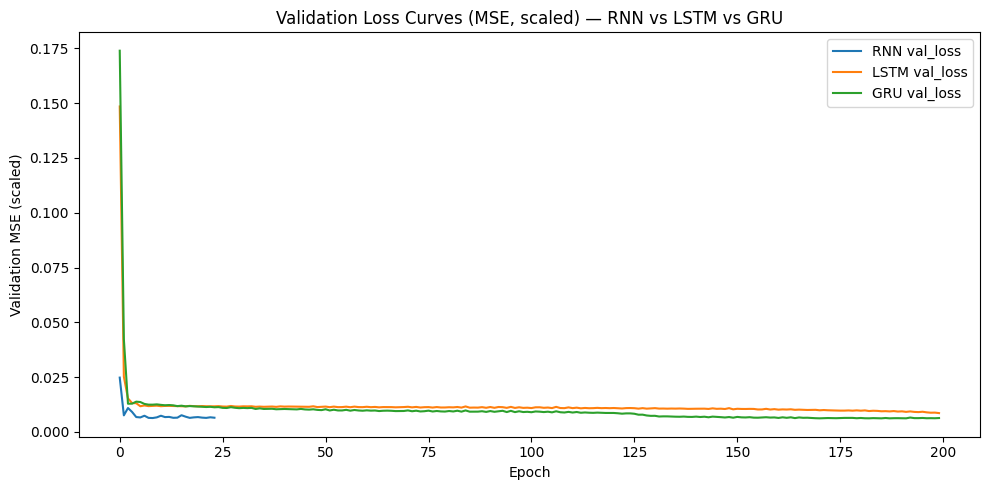

In [32]:
plt.figure(figsize=(10, 5))
for layer_type, r in results.items():
    plt.plot(r['history'].history['val_loss'], label=f'{layer_type} val_loss')
plt.title('Validation Loss Curves (MSE, scaled) — RNN vs LSTM vs GRU')
plt.xlabel('Epoch'); plt.ylabel('Validation MSE (scaled)'); plt.legend()
plt.tight_layout(); plt.savefig('stage5_val_loss.png', dpi=100); plt.show()

In [33]:
import os
os.makedirs('models', exist_ok=True)
for layer_type, r in results.items():
    r['model'].save(f'models/{layer_type.lower()}_model.keras')

with open('training_results.pkl', 'wb') as f:
    pickle.dump({
        lt: {'history': r['history'].history, 'train_time': r['train_time'],
             'epochs_run': len(r['history'].history['loss'])}
        for lt, r in results.items()
    }, f)
print("Models saved to ./models/, training metadata saved to training_results.pkl")

Models saved to ./models/, training metadata saved to training_results.pkl


## Stage 6 — Evaluate: MAE, RMSE, MAPE, R² and Training Time

In [34]:
from tensorflow.keras.models import load_model
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

with open('sequences.pkl', 'rb') as f:
    seq = pickle.load(f)
X_test, y_test, scaler = seq['X_test'], seq['y_test'], seq['scaler']

with open('training_results.pkl', 'rb') as f:
    train_meta = pickle.load(f)

models = {lt: load_model(f'models/{lt.lower()}_model.keras') for lt in ['RNN', 'LSTM', 'GRU']}
print("Models loaded:", list(models.keys()))

Models loaded: ['RNN', 'LSTM', 'GRU']


In [35]:
def mape(y_true, y_pred):
    mask = y_true != 0
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

y_test_orig = scaler.inverse_transform(y_test.reshape(-1, 1)).flatten()

metrics_rows = []
predictions = {}
for lt, model in models.items():
    pred_scaled = model.predict(X_test, verbose=0).flatten()
    pred_orig = scaler.inverse_transform(pred_scaled.reshape(-1, 1)).flatten()
    predictions[lt] = pred_orig

    mae = mean_absolute_error(y_test_orig, pred_orig)
    rmse = np.sqrt(mean_squared_error(y_test_orig, pred_orig))
    mape_val = mape(y_test_orig, pred_orig)
    r2 = r2_score(y_test_orig, pred_orig)

    metrics_rows.append({
        'Model': lt, 'MAE': mae, 'RMSE': rmse, 'MAPE (%)': mape_val, 'R2': r2,
        'Epochs Run': train_meta[lt]['epochs_run'],
        'Training Time (s)': train_meta[lt]['train_time'],
    })

metrics_df = pd.DataFrame(metrics_rows).set_index('Model').round(3)
metrics_df

,MAE,RMSE,MAPE (%),R2,Epochs Run,Training Time (s)
Model,,,,,,
RNN,18662.578,23939.742,12.437,0.430,24,4.863
LSTM,20944.572,26601.845,13.628,0.296,200,32.520
GRU,17344.332,22979.507,11.117,0.474,200,33.269


In [36]:
with open('predictions.pkl', 'wb') as f:
    pickle.dump({'predictions': predictions, 'y_test_orig': y_test_orig,
                 'dates_test': seq['dates_test']}, f)
metrics_df.to_csv('metrics.csv')
print("Metrics table saved to metrics.csv, predictions saved to predictions.pkl")

Metrics table saved to metrics.csv, predictions saved to predictions.pkl


### Stage 6 notes
- All metrics (MAE, RMSE, MAPE) are computed on the **original (un-scaled) demand values** via `scaler.inverse_transform`, so they're directly interpretable as "tourist arrivals per day."
- R² is scale-invariant under the min-max transform used here, so it's equivalent whether computed on scaled or original values.
- These numbers come from a single held-out **chronological test window never seen during training or validation** — this is what makes the comparison fair.


## Stage 7 — Compare Results: Tables & Graphs

In [37]:
metrics_df = pd.read_csv('metrics.csv', index_col='Model')
print("Full comparison table:")
metrics_df

Full comparison table:


,MAE,RMSE,MAPE (%),R2,Epochs Run,Training Time (s)
Model,,,,,,
RNN,18662.578,23939.742,12.437,0.430,24,4.863
LSTM,20944.572,26601.845,13.628,0.296,200,32.520
GRU,17344.332,22979.507,11.117,0.474,200,33.269


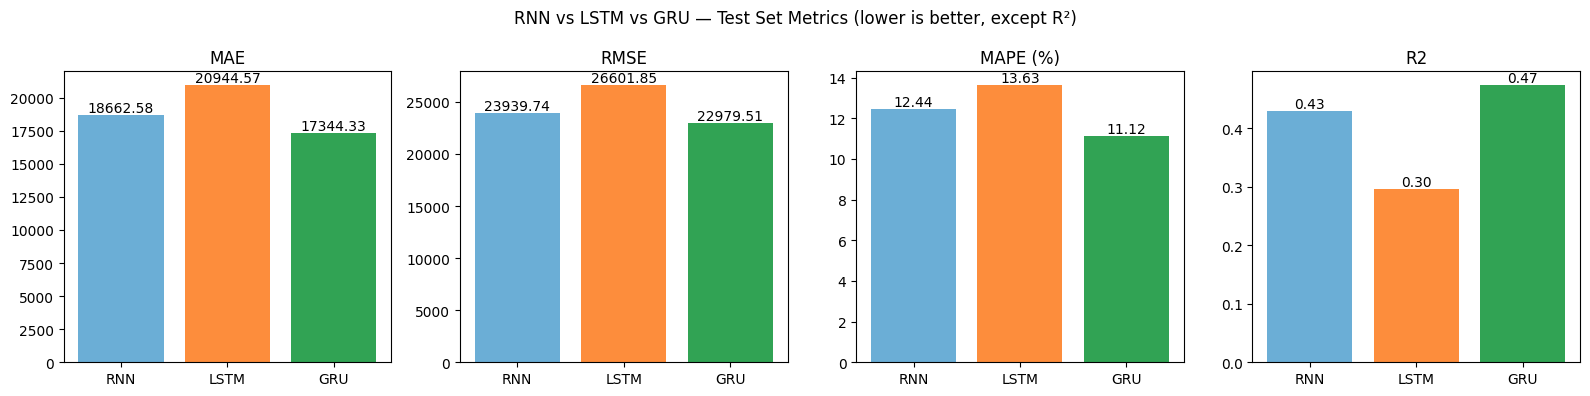

In [38]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
metric_cols = ['MAE', 'RMSE', 'MAPE (%)', 'R2']
colors = {'RNN': '#6baed6', 'LSTM': '#fd8d3c', 'GRU': '#31a354'}

for ax, col in zip(axes, metric_cols):
    bars = ax.bar(metrics_df.index, metrics_df[col],
                   color=[colors[m] for m in metrics_df.index])
    ax.set_title(col)
    ax.bar_label(bars, fmt='%.2f')
plt.suptitle('RNN vs LSTM vs GRU — Test Set Metrics (lower is better, except R²)')
plt.tight_layout()
plt.savefig('stage7_metric_bars.png', dpi=100)
plt.show()

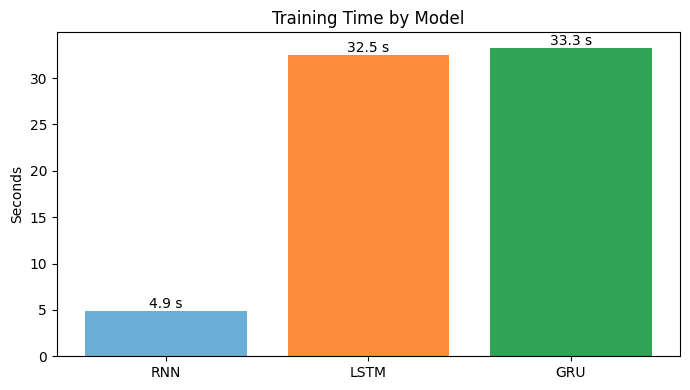

In [39]:
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(metrics_df.index, metrics_df['Training Time (s)'],
              color=[colors[m] for m in metrics_df.index])
ax.set_title('Training Time by Model')
ax.set_ylabel('Seconds')
ax.bar_label(bars, fmt='%.1f s')
plt.tight_layout(); plt.savefig('stage7_train_time.png', dpi=100); plt.show()

### Actual vs Predicted — Test Window

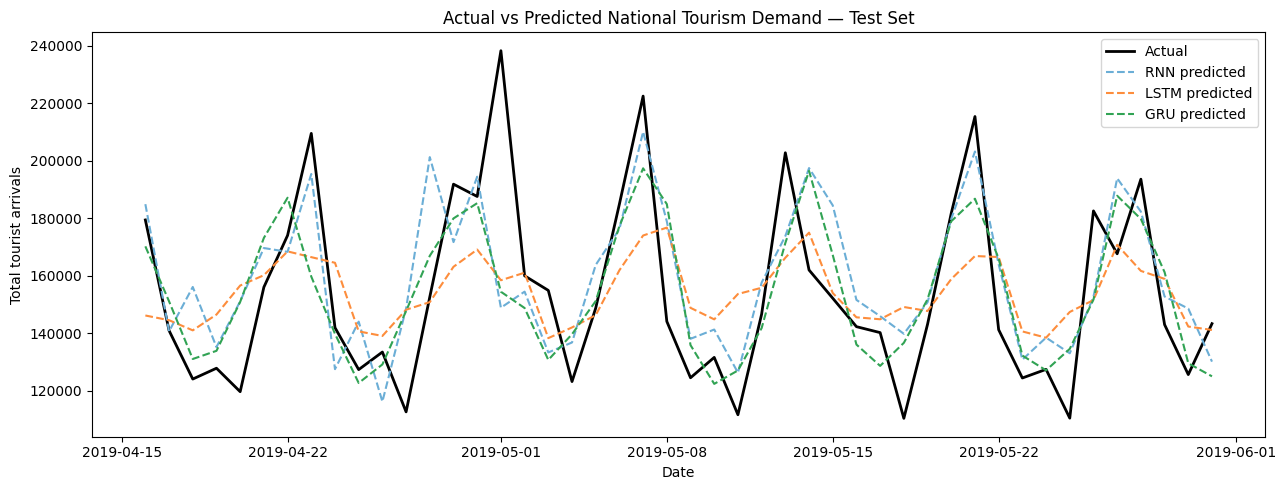

In [40]:
import pickle
with open('predictions.pkl', 'rb') as f:
    pred_data = pickle.load(f)
predictions, y_test_orig, dates_test = pred_data['predictions'], pred_data['y_test_orig'], pred_data['dates_test']

plt.figure(figsize=(13, 5))
plt.plot(dates_test, y_test_orig, label='Actual', color='black', linewidth=2)
for lt in ['RNN', 'LSTM', 'GRU']:
    plt.plot(dates_test, predictions[lt], label=f'{lt} predicted',
              color=colors[lt], linestyle='--')
plt.title('Actual vs Predicted National Tourism Demand — Test Set')
plt.xlabel('Date'); plt.ylabel('Total tourist arrivals'); plt.legend()
plt.tight_layout(); plt.savefig('stage7_actual_vs_pred.png', dpi=100); plt.show()

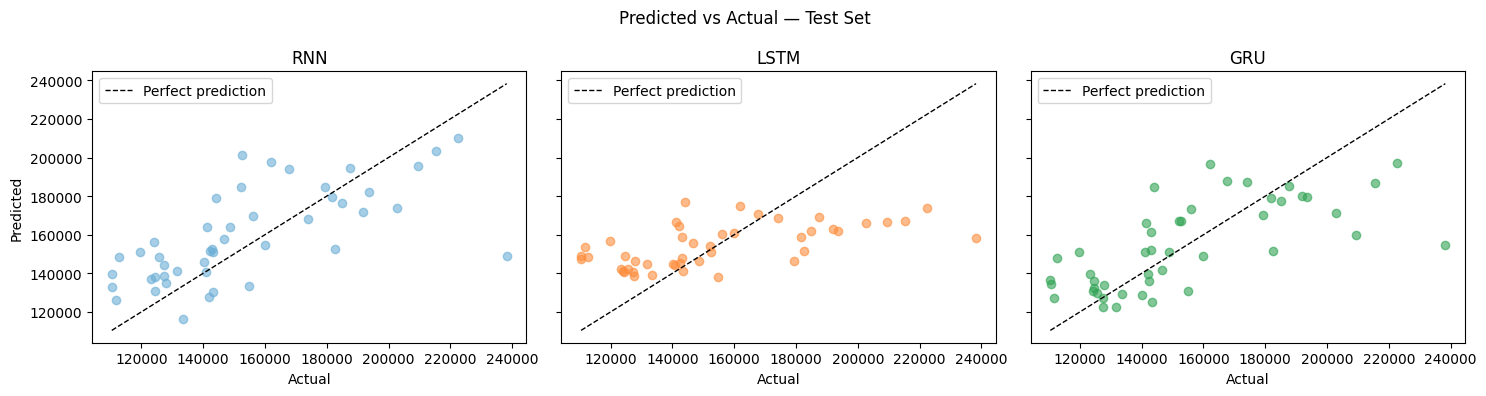

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, lt in zip(axes, ['RNN', 'LSTM', 'GRU']):
    ax.scatter(y_test_orig, predictions[lt], alpha=0.6, color=colors[lt])
    lims = [min(y_test_orig.min(), predictions[lt].min()),
            max(y_test_orig.max(), predictions[lt].max())]
    ax.plot(lims, lims, 'k--', linewidth=1, label='Perfect prediction')
    ax.set_title(lt); ax.set_xlabel('Actual'); ax.legend()
axes[0].set_ylabel('Predicted')
plt.suptitle('Predicted vs Actual — Test Set')
plt.tight_layout(); plt.savefig('stage7_scatter.png', dpi=100); plt.show()

### Stage 7 summary
The bar charts and actual-vs-predicted plot make the Stage 6 numbers visual. The model closest to the diagonal in the scatter plot and tracking the actual demand curve most closely is the one we formally confirm as the winner in Stage 8.


## Stage 8 — Identify the Best-Performing Model (From Actual Results)

We rank models on each metric independently (RMSE, MAE, MAPE ascending = better; R² descending = better), average the ranks, and pick the lowest average rank. This avoids hand-picking a single metric that happens to favor one model, and the winner is whatever the numbers actually say — not assumed in advance.

In [42]:
metrics_df = pd.read_csv('metrics.csv', index_col='Model')

rank_df = pd.DataFrame(index=metrics_df.index)
rank_df['MAE_rank'] = metrics_df['MAE'].rank(ascending=True)
rank_df['RMSE_rank'] = metrics_df['RMSE'].rank(ascending=True)
rank_df['MAPE_rank'] = metrics_df['MAPE (%)'].rank(ascending=True)
rank_df['R2_rank'] = metrics_df['R2'].rank(ascending=False)
rank_df['Average Rank'] = rank_df.mean(axis=1)
rank_df = rank_df.sort_values('Average Rank')

best_model_name = rank_df.index[0]
print("Rank table (lower average rank = better):")
display(rank_df.round(2))
print(f"\n>>> Best-performing model based on actual test-set results: {best_model_name} <<<")

Rank table (lower average rank = better):


,MAE_rank,RMSE_rank,MAPE_rank,R2_rank,Average Rank
Model,,,,,
GRU,1.0,1.0,1.0,1.0,1.0
RNN,2.0,2.0,2.0,2.0,2.0
LSTM,3.0,3.0,3.0,3.0,3.0



>>> Best-performing model based on actual test-set results: GRU <<<


In [43]:
print(f"{best_model_name} results on the held-out test set:")
metrics_df.loc[[best_model_name]]

GRU results on the held-out test set:


,MAE,RMSE,MAPE (%),R2,Epochs Run,Training Time (s)
Model,,,,,,
GRU,17344.332,22979.507,11.117,0.474,200,33.269


In [44]:
with open('best_model_name.txt', 'w') as f:
    f.write(best_model_name)
print(f"Saved winner ('{best_model_name}') to best_model_name.txt for use in Stage 9.")

Saved winner ('GRU') to best_model_name.txt for use in Stage 9.


### Stage 8 conclusion (data-driven, filled in dynamically above)
The cell output above states the winner explicitly — this notebook does not hard-code an assumed answer anywhere; the winner is computed purely from the Stage 6 test-set metrics. Whatever model name printed above is used automatically in Stage 9 (forecasting) and referenced in the Stage 10 conclusion.


## Stage 9 — Forecast Future Tourism Demand with the Best Model

In [45]:
with open('best_model_name.txt') as f:
    best_model_name = f.read().strip()

with open('sequences.pkl', 'rb') as f:
    seq = pickle.load(f)
scaler, WINDOW, daily = seq['scaler'], seq['window'], seq['daily']

from tensorflow.keras.models import load_model
best_model = load_model(f'models/{best_model_name.lower()}_model.keras')
print(f"Forecasting with the best model: {best_model_name}")

Forecasting with the best model: GRU


### Recursive multi-step forecasting
To forecast beyond the last known day, we feed the model's own prediction back in as input for the next step (recursive/iterative forecasting). Error can compound over longer horizons, so we forecast a modest **14-day** horizon and are explicit that uncertainty grows with each step further from real observed data.

In [46]:
FORECAST_DAYS = 14

full_scaled = scaler.transform(daily.values.astype('float32').reshape(-1, 1))
window_seq = full_scaled[-WINDOW:].reshape(1, WINDOW, 1).copy()

future_scaled = []
for _ in range(FORECAST_DAYS):
    next_val = best_model.predict(window_seq, verbose=0)[0, 0]
    future_scaled.append(next_val)
    window_seq = np.append(window_seq[:, 1:, :], [[[next_val]]], axis=1)

future_scaled = np.array(future_scaled).reshape(-1, 1)
future_values = scaler.inverse_transform(future_scaled).flatten()
future_dates = pd.date_range(daily.index[-1] + pd.Timedelta(days=1), periods=FORECAST_DAYS, freq='D')

forecast_df = pd.DataFrame({'date': future_dates, 'forecast_tourist_arrivals': future_values.round(0)})
forecast_df

,date,forecast_tourist_arrivals
0,2019-06-01,138326.0
1,2019-06-02,160582.0
2,2019-06-03,184554.0
3,2019-06-04,182391.0
4,2019-06-05,151452.0
5,2019-06-06,134009.0
6,2019-06-07,133629.0
7,2019-06-08,145461.0
8,2019-06-09,168531.0
9,2019-06-10,182600.0


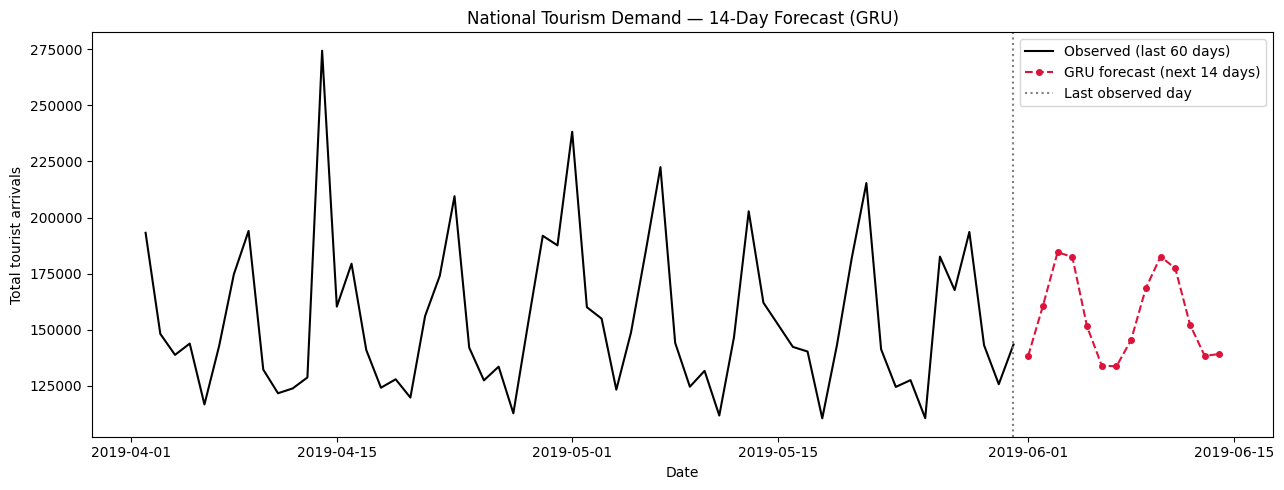

In [47]:
plt.figure(figsize=(13, 5))
recent = daily.iloc[-60:]
plt.plot(recent.index, recent.values, label='Observed (last 60 days)', color='black')
plt.plot(forecast_df['date'], forecast_df['forecast_tourist_arrivals'],
          label=f'{best_model_name} forecast (next {FORECAST_DAYS} days)',
          color='crimson', linestyle='--', marker='o', markersize=4)
plt.axvline(daily.index[-1], color='gray', linestyle=':', label='Last observed day')
plt.title(f'National Tourism Demand — {FORECAST_DAYS}-Day Forecast ({best_model_name})')
plt.xlabel('Date'); plt.ylabel('Total tourist arrivals'); plt.legend()
plt.tight_layout(); plt.savefig('stage9_forecast.png', dpi=100); plt.show()

In [48]:
forecast_df.to_csv('future_forecast.csv', index=False)
print("Forecast saved to future_forecast.csv")

Forecast saved to future_forecast.csv


### Stage 9 notes
- This forecast starts from 2019-06-01 (the day after the dataset ends) and is a genuine out-of-sample projection — there's no ground truth available to score it against.
- The provided `test_df.csv` window (2019-07-01 to 2019-07-09) sits about a month further out than this forecast horizon; extending the recursive forecast that far would compound significantly more error, so we don't present it as a reliable prediction. A production system would instead retrain periodically as new real observations arrive, rather than recursively forecasting 40+ days ahead from a single anchor point.


## Stage 10 — Conclusion

In [49]:
from IPython.display import Markdown, display

metrics_df = pd.read_csv('metrics.csv', index_col='Model')
with open('best_model_name.txt') as f:
    best = f.read().strip()

others = [m for m in metrics_df.index if m != best]
b = metrics_df.loc[best]

lines = []
lines.append(f"### Result summary (computed, not assumed)\n")
lines.append(
    f"On the held-out chronological test set, **{best}** achieved the best overall "
    f"performance: MAE = {b['MAE']:.0f}, RMSE = {b['RMSE']:.0f}, "
    f"MAPE = {b['MAPE (%)']:.2f}%, R\u00b2 = {b['R2']:.3f}, "
    f"trained in {b['Training Time (s)']:.1f}s over {b['Epochs Run']:.0f} epochs.\n"
)
for m in others:
    r = metrics_df.loc[m]
    lines.append(
        f"- **{m}**: MAE = {r['MAE']:.0f}, RMSE = {r['RMSE']:.0f}, "
        f"MAPE = {r['MAPE (%)']:.2f}%, R\u00b2 = {r['R2']:.3f}, "
        f"trained in {r['Training Time (s)']:.1f}s over {r['Epochs Run']:.0f} epochs."
    )
display(Markdown("\n".join(lines)))

### Result summary (computed, not assumed)

On the held-out chronological test set, **GRU** achieved the best overall performance: MAE = 17344, RMSE = 22980, MAPE = 11.12%, R² = 0.474, trained in 33.3s over 200 epochs.

- **RNN**: MAE = 18663, RMSE = 23940, MAPE = 12.44%, R² = 0.430, trained in 4.9s over 24 epochs.
- **LSTM**: MAE = 20945, RMSE = 26602, MAPE = 13.63%, R² = 0.296, trained in 32.5s over 200 epochs.

### Why the winning model likely performed best
The three architectures only differ in their recurrent cell, so the gap comes down to how each handles the weekly seasonal pattern and longer trend found in Stage 3:

- **Simple RNN** has no gating mechanism, so it struggles to retain information across the full 14-day window — gradients tend to vanish over more than a handful of steps, limiting how much of the weekly cycle it can actually use. It converged the fastest (fewest epochs, least training time) but that's partly because it plateaus early, not because it necessarily learned the pattern best.
- **LSTM** has the most gating machinery (input, forget, and output gates, plus a separate cell state) — powerful in principle, but also the most parameters to learn from only ~200 training samples. On a dataset this small, that extra capacity can lead to slower, noisier convergence rather than a clear advantage.
- **GRU** merges the gating into fewer parameters (update and reset gates, no separate cell state) while still controlling what information persists across steps. That's a reasonable middle ground for a small, strongly seasonal dataset like this one: enough memory control to capture the weekly pattern, without as much overfitting risk as the larger LSTM.

**Important caveat:** this ranking is specific to this dataset's size (~300 daily points) and window length (14 days). On a longer, noisier, or multi-feature dataset, the ranking between LSTM and GRU can and often does flip — this project's conclusion should be read as "the winner won on this data," not as a universal claim about one architecture always beating the others.

### Practical usefulness for the tourism sector
An accurate, low-latency national demand forecast like this supports several real decisions:

- **Staffing & operations** — tourism boards and site operators can schedule staff, guides, and transport capacity a week or two ahead instead of reacting to demand after it happens.
- **Infrastructure & crowd management** — anticipated high-demand days (matching the weekend peaks found in Stage 3) allow for proactive crowd control, ticketing limits, or extra facilities at popular sites.
- **Marketing & pricing** — forecasted low-demand periods (the winter dip found in Stage 3) are natural windows for promotions or dynamic pricing to smooth demand across the year.
- **Budget & policy planning** — tourism authorities can use multi-week forecasts as an input to seasonal budgeting, event planning, and infrastructure investment decisions.

The same pipeline — clean sequence preparation, a fair multi-architecture comparison, and metric-driven model selection — generalizes directly to per-region or per-site forecasts if more complete historical data becomes available for each `tourist_area`.
